In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

In [7]:
def ozone_model(julian_continuous, wind_u, rltv_hum, wind_v, dow_continuous, vehicle_count, blh_m):
    return ((julian_continuous - 3.872615) * wind_u) + ((rltv_hum * -0.62980855) + (94.36842 - ((wind_v * ((julian_continuous + 2.3758273) - wind_u)) + (dow_continuous + abs(((vehicle_count / -1.7585675) + blh_m) / -47.840992)))))

In [8]:
def pm25_model(msl_pressure, wind_v, t, blh_m, glbl_irad_amt, julian_continuous, air_temperature):
    return ((msl_pressure + (((wind_v / 0.017794397) + 268.34534) / (((t * blh_m) / ((blh_m * 0.19582778) + glbl_irad_amt)) + 0.18739027))) * (julian_continuous + np.log(blh_m))) / ((blh_m - air_temperature) + 228.64922)

In [22]:
def pm25_model2(air_temperature, wind_u, wind_v, julian_continuous, msl_pressure, blh_m, t):
    return (air_temperature / 2.1007636) + (abs((((((wind_u - 2.1007636) * julian_continuous) - wind_v) - 8.642212) + wind_u) * ((np.sqrt(t) - 0.77394944) - np.log(msl_pressure / blh_m))) + (julian_continuous * 2.1007636))

In [9]:
df = pd.read_csv("test_data_test.csv")
df_ozone = df.drop(columns=['pm25'])
df_pm25 = df.drop(columns=['ozone'])

X_ozone = df_ozone.drop(columns=['day'])
y_ozone = df_ozone['ozone']

X_pm25 = df_pm25.drop(columns=['day'])
y_pm25 = df_pm25['pm25']

In [23]:
y_pred_ozone = ozone_model(X_ozone['julian_continuous'], X_ozone['wind_u'], X_ozone['rltv_hum'], X_ozone['wind_v'], X_ozone['dow_continuous'], X_ozone['vehicle_count'], X_ozone['blh_m'])
y_pred_pm25 = pm25_model(X_pm25['msl_pressure'], X_pm25['wind_v'], X_pm25['t'], X_pm25['blh_m'], X_pm25['glbl_irad_amt'], X_pm25['julian_continuous'], X_pm25['air_temperature'])
y_pred_pm25_2 = pm25_model2(X_pm25['air_temperature'], X_pm25['wind_u'], X_pm25['wind_v'], X_pm25['julian_continuous'], X_pm25['msl_pressure'], X_pm25['blh_m'], X_pm25['t'])

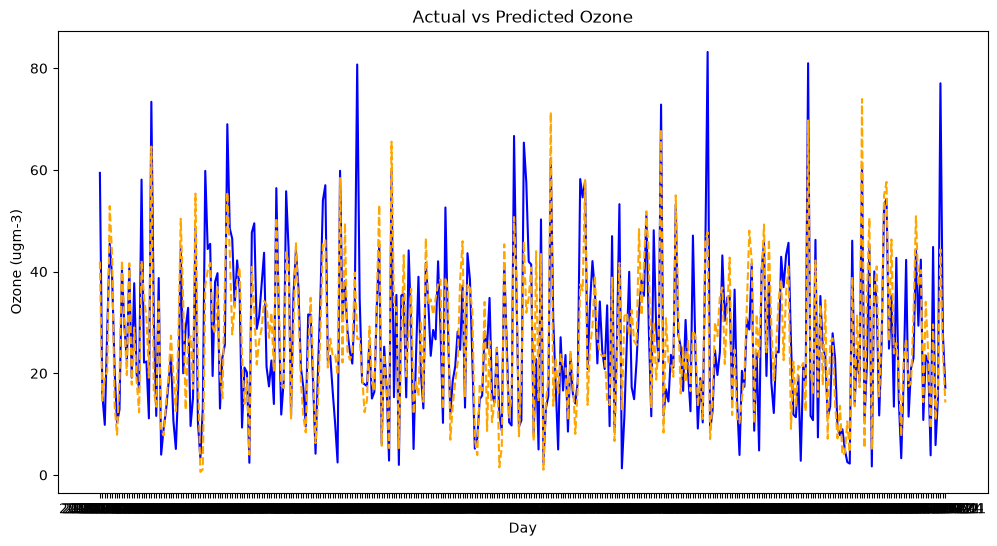

In [13]:
# plot ozone
# time series plot of actual vs predicted ozone
plt.figure(figsize=(12, 6))
plt.plot(df_ozone['day'], y_ozone, label='Actual Ozone', color='blue')
plt.plot(df_ozone['day'], y_pred_ozone, label='Predicted Ozone', color='orange', linestyle='--')
plt.xlabel('Day')
plt.ylabel('Ozone (ugm-3)')
plt.title('Actual vs Predicted Ozone')
plt.show()

In [15]:
# mse, r2
mse_ozone = mean_squared_error(y_ozone, y_pred_ozone)
r2_ozone = r2_score(y_ozone, y_pred_ozone)

print(f"Ozone Model - Mean Squared Error: {mse_ozone:.4f}")
print(f"Ozone Model - R-squared: {r2_ozone:.4f}")

Ozone Model - Mean Squared Error: 84.7596
Ozone Model - R-squared: 0.6828


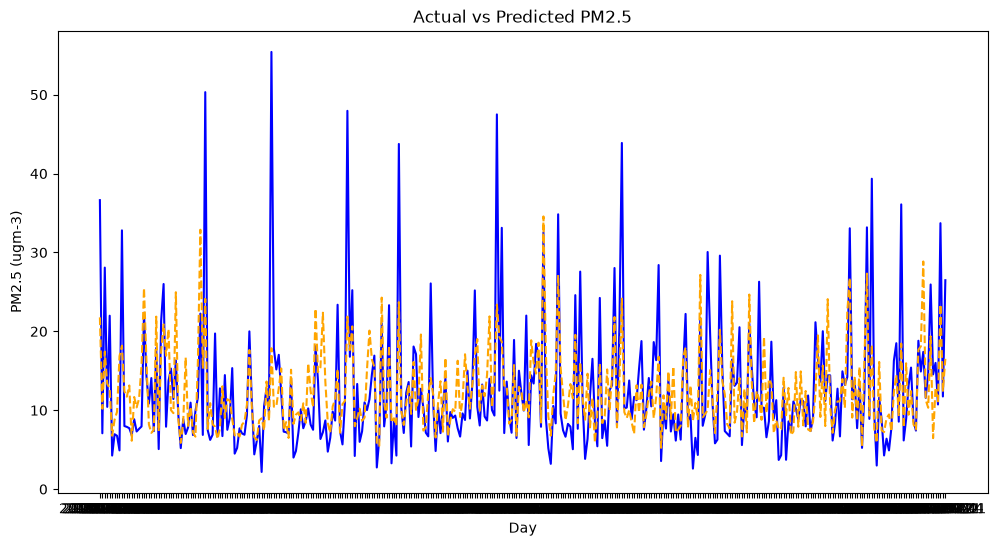

In [16]:
# plot pm25
# time series plot of actual vs predicted pm25
plt.figure(figsize=(12, 6))
plt.plot(df_pm25['day'], y_pm25, label='Actual PM2.5', color='blue')
plt.plot(df_pm25['day'], y_pred_pm25, label='Predicted PM2.5', color='orange', linestyle='--')
plt.xlabel('Day')
plt.ylabel('PM2.5 (ugm-3)')
plt.title('Actual vs Predicted PM2.5')
plt.show()

In [18]:
# mse, r2 (pm25)
mse_pm25 = mean_squared_error(y_pm25, y_pred_pm25)
r2_pm25 = r2_score(y_pm25, y_pred_pm25)

print(f"PM2.5 Model - Mean Squared Error: {mse_pm25:.4f}")
print(f"PM2.5 Model - R-squared: {r2_pm25:.4f}")

PM2.5 Model - Mean Squared Error: 37.9546
PM2.5 Model - R-squared: 0.4416


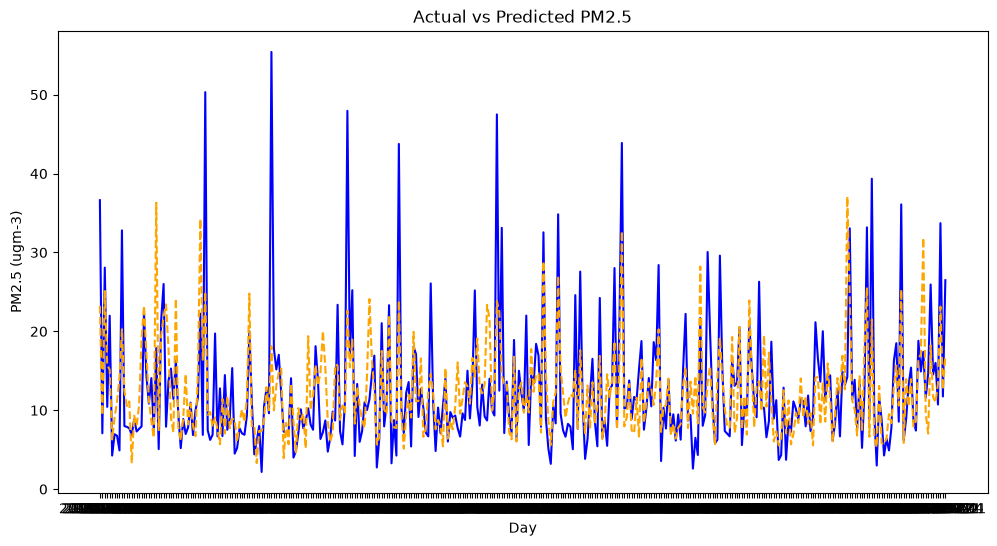

In [24]:
# plot pm25
# time series plot of actual vs predicted pm25
plt.figure(figsize=(12, 6))
plt.plot(df_pm25['day'], y_pm25, label='Actual PM2.5', color='blue')
plt.plot(df_pm25['day'], y_pred_pm25_2, label='Predicted PM2.5', color='orange', linestyle='--')
plt.xlabel('Day')
plt.ylabel('PM2.5 (ugm-3)')
plt.title('Actual vs Predicted PM2.5')
plt.show()

In [25]:
# mse, r2 (pm25)
mse_pm25_2 = mean_squared_error(y_pm25, y_pred_pm25_2)
r2_pm25_2 = r2_score(y_pm25, y_pred_pm25_2)

print(f"PM2.5 Model - Mean Squared Error: {mse_pm25_2:.4f}")
print(f"PM2.5 Model - R-squared: {r2_pm25_2:.4f}")

PM2.5 Model - Mean Squared Error: 38.0014
PM2.5 Model - R-squared: 0.4409
